
# 04 - Movement Analysis

## Objective
Analyze body movement using the extracted MediaPipe pose landmarks.

## Tasks
1. Load the extracted landmark dataset.
2. Identify important body joints.
3. Calculate joint angles.
4. Analyze movement across sampled frames.
5. Prepare movement features for exercise performance analysis.

## Limitation
Joint angles can describe movement patterns, but they do not independently diagnose injuries or validate injury risk.


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
project_folder = Path("..")
output_folder = project_folder / "outputs"

landmarks_path = output_folder / "landmarks_all.csv"

landmarks_df = pd.read_csv(landmarks_path)

print("Dataset shape:", landmarks_df.shape)
print("Videos:", landmarks_df["video_name"].nunique())
print("Landmark IDs:", landmarks_df["landmark_id"].nunique())

display(landmarks_df.head())

Dataset shape: (99165, 8)
Videos: 645
Landmark IDs: 33


,video_name,category,frame_number,landmark_id,x,y,z,visibility
0,barbell biceps curl_1.mp4,barbell biceps curl,0,0,0.498279,0.229613,-0.210639,0.999779
1,barbell biceps curl_1.mp4,barbell biceps curl,0,1,0.505566,0.210049,-0.202190,0.999703
2,barbell biceps curl_1.mp4,barbell biceps curl,0,2,0.511841,0.208941,-0.202359,0.999664
3,barbell biceps curl_1.mp4,barbell biceps curl,0,3,0.518395,0.207871,-0.202618,0.999581
4,barbell biceps curl_1.mp4,barbell biceps curl,0,4,0.495593,0.211241,-0.184685,0.999646


In [ ]:
sample_video = landmarks_df["video_name"].iloc[0]
sample_frame = landmarks_df[landmarks_df["video_name"] == sample_video]["frame_number"].iloc[0]

frame_landmarks = landmarks_df[
    (landmarks_df["video_name"] == sample_video)
    & (landmarks_df["frame_number"] == sample_frame)]
display(frame_landmarks[
        ["landmark_id", "x", "y", "visibility"]].head(20))


,landmark_id,x,y,visibility
0,0,0.498279,0.229613,0.999779
1,1,0.505566,0.210049,0.999703
2,2,0.511841,0.208941,0.999664
3,3,0.518395,0.207871,0.999581
4,4,0.495593,0.211241,0.999646
5,5,0.493407,0.211272,0.999567
6,6,0.491246,0.211527,0.999493
7,7,0.532480,0.214389,0.999712
8,8,0.492998,0.217201,0.999652
9,9,0.509811,0.247437,0.999673


In [5]:
shoulder = frame_landmarks[frame_landmarks["landmark_id"] == 11].iloc[0]
elbow = frame_landmarks[frame_landmarks["landmark_id"] == 13].iloc[0]
wrist = frame_landmarks[frame_landmarks["landmark_id"] == 15].iloc[0]

print("Shoulder:", shoulder[["x", "y"]].to_dict())
print("Elbow:", elbow[["x", "y"]].to_dict())
print("Wrist:", wrist[["x", "y"]].to_dict())


Shoulder: {'x': 0.5792137384414673, 'y': 0.3397630453109741}
Elbow: {'x': 0.5810729265213013, 'y': 0.4295776784420013}
Wrist: {'x': 0.5623698830604553, 'y': 0.2993668913841247}


In [6]:

A = np.array([shoulder["x"], shoulder["y"]])
B = np.array([elbow["x"], elbow["y"]])
C = np.array([wrist["x"], wrist["y"]])

vector_1 = A - B
vector_2 = C - B

print("Shoulder-to-elbow vector:", vector_1)
print("Elbow-to-wrist vector:", vector_2)

Shoulder-to-elbow vector: [-0.00185919 -0.08981463]
Elbow-to-wrist vector: [-0.01870304 -0.13021079]


In [7]:
dot_product = np.dot(vector_1, vector_2)

length_1 = np.linalg.norm(vector_1)
length_2 = np.linalg.norm(vector_2)
cos_angle = dot_product / (length_1 * length_2)

cos_angle = np.clip(cos_angle, -1.0, 1.0)
angle_radians = np.arccos(cos_angle)
angle_degrees = np.degrees(angle_radians)

print(f"Left elbow angle: {angle_degrees:.2f} degrees")


Left elbow angle: 6.99 degrees


In [8]:
def calculate_angle(point_a, point_b, point_c):
    A = np.array(point_a, dtype=float)
    B = np.array(point_b, dtype=float)
    C = np.array(point_c, dtype=float)

    vector_1 = A - B
    vector_2 = C - B
    length_1 = np.linalg.norm(vector_1)
    length_2 = np.linalg.norm(vector_2)

    # Avoid division by zero
    if length_1 == 0 or length_2 == 0:
        return np.nan

    cos_angle = np.dot(vector_1, vector_2) / (
        length_1 * length_2
    )

    cos_angle = np.clip(cos_angle, -1.0, 1.0)

    angle_radians = np.arccos(cos_angle)
    angle_degrees = np.degrees(angle_radians)

    return angle_degrees

In [9]:

shoulder_point = (shoulder["x"],shoulder["y"])

elbow_point = (elbow["x"],elbow["y"])

wrist_point = (wrist["x"],wrist["y"])

left_elbow_angle = calculate_angle(shoulder_point,elbow_point,wrist_point)

print(f"Left elbow angle: {left_elbow_angle:.2f} degrees")


Left elbow angle: 6.99 degrees


In [10]:
# MediaPipe landmark IDs
JOINT_IDS = {
    "left_shoulder": 11,
    "left_elbow": 13,
    "left_wrist": 15,
    "right_shoulder": 12,
    "right_elbow": 14,
    "right_wrist": 16,
}

In [11]:
def get_joint_point(frame_data, landmark_id):
    """Return the (x, y) coordinates of a visible joint."""

    joint = frame_data[
        frame_data["landmark_id"] == landmark_id
    ]

    if joint.empty:
        return None

    joint = joint.iloc[0]

    if (
        pd.isna(joint["x"])
        or pd.isna(joint["y"])
        or joint["visibility"] < 0.5
    ):
        return None

    return (joint["x"], joint["y"])


def get_elbow_angle(frame_data, shoulder_id, elbow_id, wrist_id):
    shoulder = get_joint_point(frame_data, shoulder_id)
    elbow = get_joint_point(frame_data, elbow_id)
    wrist = get_joint_point(frame_data, wrist_id)

    if shoulder is None or elbow is None or wrist is None:
        return np.nan

    return calculate_angle(shoulder, elbow, wrist)


angle_records = []

group_columns = ["video_name", "category", "frame_number"]

for (video_name, category, frame_number), frame_data in (
    landmarks_df.groupby(group_columns)
):
    left_angle = get_elbow_angle(
        frame_data, 11, 13, 15
    )

    right_angle = get_elbow_angle(
        frame_data, 12, 14, 16
    )

    angle_records.append({
        "video_name": video_name,
        "category": category,
        "frame_number": frame_number,
        "left_elbow_angle": left_angle,
        "right_elbow_angle": right_angle,
    })

angles_df = pd.DataFrame(angle_records)

print("Frames analyzed:", len(angles_df))
print("Videos analyzed:", angles_df["video_name"].nunique())

display(angles_df.head(10))


Frames analyzed: 3005
Videos analyzed: 645


,video_name,category,frame_number,left_elbow_angle,right_elbow_angle
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,0,136.532366,NaN
1,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,29,119.236965,NaN
2,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,59,166.130163,NaN
3,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,89,142.758576,NaN
4,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,119,141.210317,NaN
5,barbell biceps curl_1.mp4,barbell biceps curl,0,6.987998,22.721101
6,barbell biceps curl_1.mp4,barbell biceps curl,28,44.710857,68.045829
7,barbell biceps curl_1.mp4,barbell biceps curl,56,160.578317,165.659820
8,barbell biceps curl_1.mp4,barbell biceps curl,84,163.064091,165.151458
9,barbell biceps curl_1.mp4,barbell biceps curl,113,5.200463,19.162531


In [12]:

# Check missing values
print("Total frames:", len(angles_df))

print(
    "Missing left elbow angles:",
    angles_df["left_elbow_angle"].isna().sum()
)

print(
    "Missing right elbow angles:",
    angles_df["right_elbow_angle"].isna().sum()
)

# Statistical summary
display(
    angles_df[
        ["left_elbow_angle", "right_elbow_angle"]
    ].describe().round(2)
)

# Check angles outside the expected geometric range
for column in ["left_elbow_angle", "right_elbow_angle"]:
    invalid = angles_df[
        (angles_df[column] < 0) |
        (angles_df[column] > 180)
    ]

    print(f"{column} - invalid values:", len(invalid))


Total frames: 3005
Missing left elbow angles: 655
Missing right elbow angles: 795


,left_elbow_angle,right_elbow_angle
count,2350.00,2210.00
mean,128.74,127.97
std,54.60,55.16
min,0.01,0.02
25%,92.38,85.91
50%,156.26,155.24
75%,170.92,172.57
max,180.00,180.00


left_elbow_angle - invalid values: 0
right_elbow_angle - invalid values: 0


In [13]:

angles_output_path = output_folder / "movement_angles.csv"

angles_df.to_csv(angles_output_path, index=False)

print("Saved to:", angles_output_path.resolve())
print("Rows saved:", len(angles_df))


Saved to: C:\athlete-performance-injury-risk\outputs\movement_angles.csv
Rows saved: 3005


In [14]:

angle_records = []

for (video_name, category, frame_number), frame_data in (
    landmarks_df.groupby(["video_name", "category", "frame_number"])
):
    record = {
        "video_name": video_name,
        "category": category,
        "frame_number": frame_number,
    }

    # Elbow angles
    record["left_elbow_angle"] = get_elbow_angle(
        frame_data, 11, 13, 15
    )
    record["right_elbow_angle"] = get_elbow_angle(
        frame_data, 12, 14, 16
    )

    # Knee angles: hip -> knee -> ankle
    record["left_knee_angle"] = get_elbow_angle(
        frame_data, 23, 25, 27
    )
    record["right_knee_angle"] = get_elbow_angle(
        frame_data, 24, 26, 28
    )

    # Hip angles: shoulder -> hip -> knee
    record["left_hip_angle"] = get_elbow_angle(
        frame_data, 11, 23, 25
    )
    record["right_hip_angle"] = get_elbow_angle(
        frame_data, 12, 24, 26
    )

    angle_records.append(record)

angles_df = pd.DataFrame(angle_records)

print("Frames analyzed:", len(angles_df))
print("Videos analyzed:", angles_df["video_name"].nunique())

display(angles_df.head(10))


Frames analyzed: 3005
Videos analyzed: 645


,video_name,category,frame_number,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,0,136.532366,NaN,76.303009,61.115009,167.502841,154.760229
1,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,29,119.236965,NaN,35.128447,NaN,71.053439,NaN
2,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,59,166.130163,NaN,28.303478,NaN,52.390251,NaN
3,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,89,142.758576,NaN,51.370671,NaN,124.260108,NaN
4,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,119,141.210317,NaN,51.363290,NaN,61.971812,NaN
5,barbell biceps curl_1.mp4,barbell biceps curl,0,6.987998,22.721101,170.063252,175.538028,176.429518,173.544925
6,barbell biceps curl_1.mp4,barbell biceps curl,28,44.710857,68.045829,NaN,168.955132,175.229511,173.427927
7,barbell biceps curl_1.mp4,barbell biceps curl,56,160.578317,165.659820,NaN,NaN,177.455960,172.906028
8,barbell biceps curl_1.mp4,barbell biceps curl,84,163.064091,165.151458,NaN,NaN,175.692203,174.740348
9,barbell biceps curl_1.mp4,barbell biceps curl,113,5.200463,19.162531,NaN,NaN,NaN,NaN


In [15]:

angle_columns = [
    "left_elbow_angle",
    "right_elbow_angle",
    "left_knee_angle",
    "right_knee_angle",
    "left_hip_angle",
    "right_hip_angle",
]

# Count valid and missing angles
quality_summary = pd.DataFrame({
    "valid_count": angles_df[angle_columns].count(),
    "missing_count": angles_df[angle_columns].isna().sum(),
    "valid_percentage": (
        angles_df[angle_columns].count()
        / len(angles_df) * 100
    ).round(2),
})

display(quality_summary)

# Statistical summary
display(angles_df[angle_columns].describe().round(2))

# Check for angles outside 0–180 degrees
for column in angle_columns:
    invalid_count = (
        (angles_df[column] < 0) |
        (angles_df[column] > 180)
    ).sum()

    print(f"{column}: {invalid_count} invalid angles")


,valid_count,missing_count,valid_percentage
left_elbow_angle,2350,655,78.20
right_elbow_angle,2210,795,73.54
left_knee_angle,1262,1743,42.00
right_knee_angle,1280,1725,42.60
left_hip_angle,1844,1161,61.36
right_hip_angle,1770,1235,58.90


,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle
count,2350.00,2210.00,1262.00,1280.00,1844.00,1770.00
mean,128.74,127.97,144.73,141.45,141.30,140.93
std,54.60,55.16,37.54,40.77,41.49,41.85
min,0.01,0.02,4.23,0.28,0.78,2.67
25%,92.38,85.91,125.73,117.68,125.74,119.35
50%,156.26,155.24,159.31,157.43,156.88,157.91
75%,170.92,172.57,174.71,173.85,173.09,173.50
max,180.00,180.00,179.99,179.97,179.98,179.99


left_elbow_angle: 0 invalid angles
right_elbow_angle: 0 invalid angles
left_knee_angle: 0 invalid angles
right_knee_angle: 0 invalid angles
left_hip_angle: 0 invalid angles
right_hip_angle: 0 invalid angles


In [16]:

# Check visibility of the joints needed for knee angles

required_joints = {
    "left_hip": 23,
    "left_knee": 25,
    "left_ankle": 27,
    "right_hip": 24,
    "right_knee": 26,
    "right_ankle": 28,
}

visibility_summary = []

for joint_name, joint_id in required_joints.items():
    joint_data = landmarks_df[
        landmarks_df["landmark_id"] == joint_id
    ]

    visible_count = (
        joint_data["visibility"].ge(0.5).sum()
    )

    visibility_summary.append({
        "joint": joint_name,
        "visible_frames": visible_count,
        "total_frames": len(angles_df),
        "visible_percentage": round(
            visible_count / len(angles_df) * 100, 2
        ),
    })

visibility_df = pd.DataFrame(visibility_summary)

display(visibility_df)


,joint,visible_frames,total_frames,visible_percentage
0,left_hip,2927,3005,97.40
1,left_knee,1845,3005,61.40
2,left_ankle,1384,3005,46.06
3,right_hip,2928,3005,97.44
4,right_knee,1770,3005,58.90
5,right_ankle,1373,3005,45.69


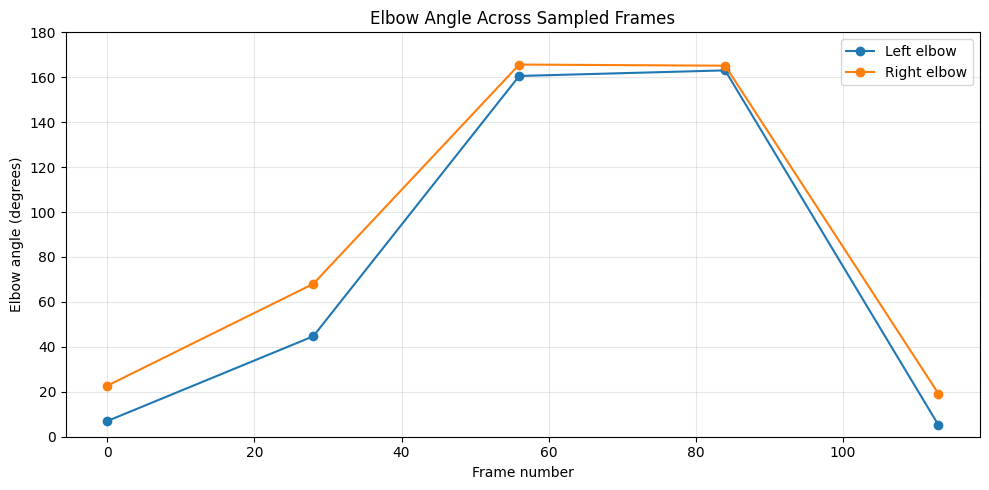

Video: barbell biceps curl_1.mp4
Sampled frames: 5


In [19]:
exercise_name = "barbell biceps curl"

exercise_data = angles_df[
    angles_df["category"] == exercise_name
].copy()

# Select one video from this exercise category
sample_video_name = exercise_data["video_name"].iloc[0]

video_data = exercise_data[
    exercise_data["video_name"] == sample_video_name
].sort_values("frame_number")

plt.figure(figsize=(10, 5))

plt.plot(
    video_data["frame_number"],
    video_data["left_elbow_angle"],
    marker="o",
    label="Left elbow"
)

plt.plot(
    video_data["frame_number"],
    video_data["right_elbow_angle"],
    marker="o",
    label="Right elbow"
)

plt.xlabel("Frame number")
plt.ylabel("Elbow angle (degrees)")
plt.title("Elbow Angle Across Sampled Frames")
plt.ylim(0, 180)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Video:", sample_video_name)
print("Sampled frames:", len(video_data))


In [20]:

angles_output_path = output_folder / "movement_angles.csv"

angles_df.to_csv(angles_output_path, index=False)

print("Saved:", angles_output_path.resolve())
print("Total rows:", len(angles_df))
print("Total videos:", angles_df["video_name"].nunique())
print("Total angle features:", len(angle_columns))


Saved: C:\athlete-performance-injury-risk\outputs\movement_angles.csv
Total rows: 3005
Total videos: 645
Total angle features: 6


In [21]:

# Summarize joint angles for each exercise category

angle_columns = [
    "left_elbow_angle",
    "right_elbow_angle",
    "left_knee_angle",
    "right_knee_angle",
    "left_hip_angle",
    "right_hip_angle",
]

exercise_summary = (
    angles_df
    .groupby("category")[angle_columns]
    .agg(["mean", "std", "count"])
    .round(2)
)

display(exercise_summary)


left_elbow_angle              right_elbow_angle         \
                                mean    std count              mean    std   
category                                                                     
barbell biceps curl           113.13  66.73   245            115.82  65.98   
bench press                   130.37  47.94   178            137.32  38.30   
chest fly machine             131.42  40.52   130            116.86  48.82   
deadlift                      170.59  19.59   106            174.26   7.14   
decline bench press           134.18  48.83    31            124.78  59.05   
hammer curl                   129.67  60.72    77            132.93  57.30   
hip thrust                    143.09  38.13    59            116.76  47.41   
incline bench press           116.48  53.46   112            109.93  54.37   
lat pulldown                  115.52  56.55   176            115.28  57.30   
lateral raise                 163.42  26.91   162            163.79  19.18   
leg extension                 162.96  29.03    85            156.17  36.38   
leg raises                    134.61  44.65    74            121.70  57.33   
plank                         115.56  32.48    14             96.18  21.72   
pull Up                       121.13  59.02   113            119.53  60.90   
push-up                       140.01  42.80   224            138.89  45.02   
romanian deadlift             166.87  11.39    34            171.36   6.18   
russian twist                  87.75  42.46    44             79.51  48.04   
shoulder press                 72.18  58.47    84             81.45  56.39   
squat                          77.87  68.52   106             62.97  63.86   
t bar row                     163.20  16.27    80            167.42  13.20   
tricep Pushdown               117.66  51.91   146            130.19  46.66   
tricep dips                   135.02  38.78    70            150.90  31.52   

                          left_knee_angle              right_knee_angle  \
                    count            mean    std count             mean   
category                                                                  
barbell biceps curl   227          171.92  21.55    56           172.57   
bench press           138          133.87  36.43   111           124.22   
chest fly machine     128          137.39  23.65    64           152.69   
deadlift              129          159.58  25.14   116           159.66   
decline bench press    32          146.82  19.43    13           153.66   
hammer curl            67          168.57  29.00    44           168.04   
hip thrust             61           92.32  41.13    70            99.41   
incline bench press   110          125.60  42.98    40           112.37   
lat pulldown          169          114.12  39.40    67            98.43   
lateral raise         162          164.08  37.60    31           169.92   
leg extension          65          133.37  26.82    94           126.56   
leg raises             94          163.55  27.79    49           158.67   
plank                  29          158.41  18.84     8           159.31   
pull Up               101          166.99  24.05    56           164.55   
push-up               178          161.22  14.95   120           134.87   
romanian deadlift      30          160.92  27.15    27           160.54   
russian twist          48          100.99  35.05    37            91.76   
shoulder press         79          118.00  16.73    18           137.41   
squat                  91          138.93  47.78    97           141.05   
t bar row              93          168.19  13.24    64           162.27   
tricep Pushdown       139          165.31  10.35    36           153.24   
tricep dips            40          145.44  26.86    44           136.59   

                                 left_hip_angle              right_hip_angle  \
                       std count           mean    std count            mean   
category                         

In [22]:

summary_path = output_folder / "exercise_angle_summary.csv"

exercise_summary.to_csv(summary_path)

print("Saved:", summary_path.resolve())
print("Exercise categories:", angles_df["category"].nunique())


Saved: C:\athlete-performance-injury-risk\outputs\exercise_angle_summary.csv
Exercise categories: 22


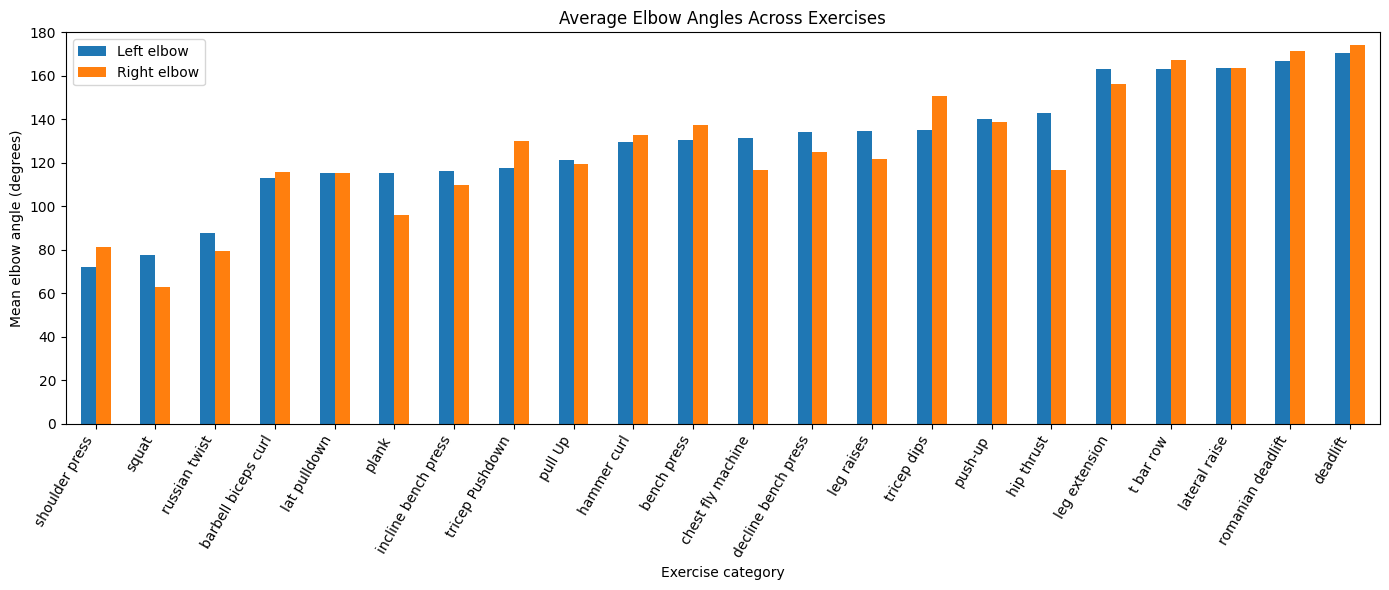

Graph saved to: C:\athlete-performance-injury-risk\outputs\exercise_elbow_comparison.png


In [23]:

# Calculate mean elbow angles for each exercise
elbow_summary = (
    angles_df
    .groupby("category")[
        ["left_elbow_angle", "right_elbow_angle"]
    ]
    .mean()
    .sort_values("left_elbow_angle")
)

elbow_summary.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Average Elbow Angles Across Exercises")
plt.xlabel("Exercise category")
plt.ylabel("Mean elbow angle (degrees)")
plt.xticks(rotation=60, ha="right")
plt.ylim(0, 180)
plt.legend(["Left elbow", "Right elbow"])
plt.tight_layout()

# Save before showing
elbow_plot_path = output_folder / "exercise_elbow_comparison.png"
plt.savefig(elbow_plot_path, dpi=300, bbox_inches="tight")

plt.show()

print("Graph saved to:", elbow_plot_path.resolve())


### Observations from Elbow Angle Comparison

- Mean left and right elbow angles vary across exercise categories.
- Some exercises show differences between the average angles of the two elbows.
- Higher or lower average angles describe the sampled body positions; they do not independently indicate correct or incorrect exercise technique.
- Missing angle values may occur when one or more required landmarks are not sufficiently visible.
- Only five frames were sampled per video, so these averages may not represent the complete movement cycle.

### Interpretation

The comparison provides an initial overview of elbow movement patterns across exercise categories. Further analysis using temporally ordered frames, reliable landmark tracking, and validated movement-quality labels would be needed to evaluate exercise technique more rigorously.